# 04_business_impact.ipynb

Translate model probabilities into business decisions and estimated financial impact.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "Python":
    PROJECT_ROOT = PROJECT_ROOT.parent
df = pd.read_csv(PROJECT_ROOT / "Data" / "Cleaned" / "credit_risk_clean.csv")
artifact = joblib.load(PROJECT_ROOT / "Python" / "credit_risk_model.joblib")
model = artifact["model"]
X_test = artifact["X_test"]
y_test = artifact["y_test"]
num = artifact["num"]
cat = artifact["cat"]
proba = model.predict_proba(X_test)[:, 1]
amounts = X_test["loan_amnt"].values
actual = y_test.values
print("Test rows:", len(X_test), "Default rows:", int(actual.sum()))
print("Probability preview:")
print(pd.DataFrame({"default_probability": proba}).head())

Test rows: 6482 Default rows: 1418
Probability preview:
   default_probability
0             0.154104
1             0.215420
2             0.047709
3             0.111056
4             0.982891


## Business assumptions

LGD is loss given default and MARGIN is the expected return on a performing loan. The data has no repayment history, so these are explicit assumptions.

In [2]:
LGD = 0.25
MARGIN = 0.08
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    decline = proba >= threshold
    bad_avoided = amounts[decline & (actual == 1)].sum()
    good_lost = amounts[decline & (actual == 0)].sum()
    rows.append({
        "threshold": threshold,
        "loans_declined": int(decline.sum()),
        "bad_$_avoided": bad_avoided,
        "good_$_turned_away": good_lost,
        "net_benefit": bad_avoided * LGD - good_lost * MARGIN,
    })
impact = pd.DataFrame(rows)
print(impact.to_string(index=False))

 threshold  loans_declined  bad_$_avoided  good_$_turned_away  net_benefit
       0.2            2190       13937025             9031725   2761718.25
       0.3            1578       13158325             4513325   2928515.25
       0.4            1308       12686000             2426600   2977372.00
       0.5            1138       12258725              952450   2988485.25
       0.6            1054       11958525              316425   2964317.25
       0.7             999       11509800              116500   2868130.00


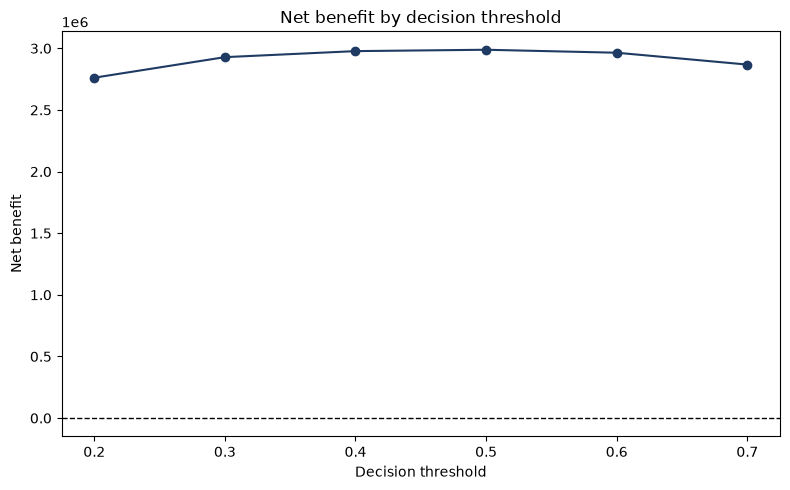

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(impact["threshold"], impact["net_benefit"], marker="o", color="#1F3B63")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Net benefit")
ax.set_title("Net benefit by decision threshold")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "Images" / "py-net-benefit.png", dpi=150)
plt.show()

> At a 0.40 decision threshold, the model declines approximately 1,297 of 6,482 applications, avoiding $12.7M in defaulted loans while turning away $2.18M of good business. Net benefit is approximately $3.0M on this test sample.

In [5]:
out = df.copy()
out["default_probability"] = model.predict_proba(df[num + cat])[:, 1]
out["risk_tier"] = pd.cut(out["default_probability"], [0, 0.2, 0.4, 0.6, 1.0], labels=["Low", "Medium", "High", "Very High"])
out.to_csv(PROJECT_ROOT / "Data" / "Cleaned" / "credit_risk_scored.csv", index=False)
print("Scored rows:", len(out))
print(out[["default_probability", "risk_tier"]].head())


Scored rows: 32409
   default_probability  risk_tier
0             0.215263     Medium
1             0.963088  Very High
2             0.972867  Very High
3             0.952884  Very High
4             0.911514  Very High
